# Circuit diagrams in Jupyter

Install `pip install -e ".[draw]"` once. Each final expression below displays an SVG drawing inline. The renderer is adapted from sircuitenum; ground and source polarity follow the `Circuit` conventions.

In [1]:
from circuit_quantization import Branch, Circuit, draw_circuit_diagram

## Voltage-driven junction

The plus terminal is always at the source node, even when the source branch points toward ground.

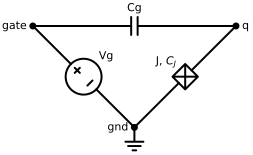

In [2]:
driven = Circuit([
    Branch("J", "q", "gnd", C=80e-15, EJ=12),
    Branch("Cg", "q", "gate", C=5e-15),
    Branch("Vg", "gate", "gnd", V=0.01),
], ground="gnd")
draw_circuit_diagram(driven)

## Parallel branches

The boxed junction includes its intrinsic capacitance. Inductor capacitance is drawn as a separate parallel element, while remaining an attribute of the same branch in the model.

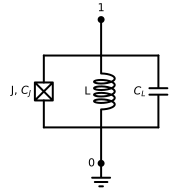

In [3]:
fluxonium = Circuit([
    Branch("J", 1, 0, C=10e-15, EJ=8),
    Branch("L", 1, 0, C=2e-15, L=200e-9),
], ground=0)
draw_circuit_diagram(fluxonium, layout={1: (0, 1), 0: (0, 0)})

## Floating circuit

Omit `ground` for a floating circuit; no ground symbol is drawn.

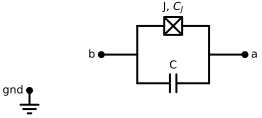

In [4]:
floating = Circuit([
    Branch("J", "a", "b", C=80e-15, EJ=12),
    Branch("C", "b", "a", C=20e-15),
])
draw_circuit_diagram(floating)

Save a drawing with `draw_circuit_diagram(driven, "driven.svg")` (also `.pdf` or `.png`). For a high-resolution PNG, use `drawing = draw_circuit_diagram(driven)` followed by `drawing.save("driven.png", dpi=200)`.